# Task 3 – Notebook 5: final comparison of the six methods and AMC
All six methods are evaluated on the **same 300 channel drops** at every $P_{\max}$ = 15…40 dBm (1 dB steps) by `experiments/run_task3.py`; this notebook only loads the results.

Metrics: sum rate, % users with $R_u\ge1$ Mbps, Jain's index $J=(\sum R_u)^2/(U\sum R_u^2)$ per drop (mean), 5th percentile of all user rates (pooled over drops and users), median computation time per drop (CPU, 1 thread; method 4 = MILP + KKT, method 6 = DNN + KKT; first-call overheads excluded by using the median), and correct sentences per second.

**AMC link** (Task 1 `AMC` class and AWGN look-up table, unchanged): for every RB the SNR is $p_n a_{u,n}$, the AMC picks the highest-efficiency MCS with BLER ≤ 10 %, and sentences/s of an RB = $B\,\eta\,(1-\mathrm{BLER})/\bar b$ with $B$=180 ksym/s per RB (assumption), $\eta$ = efficiency of the chosen MCS, $\bar b$ = 322.1 information bits per sentence (mean Huffman length of the Task 1 test sentences). RBs with undefined BLER (SNR below the table) or zero power deliver nothing.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().resolve().parents[1]
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
torch.set_num_threads(1)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
from task3_resource.system import P, dbm_to_w, draw_channels, rb_rates, user_rates, POWER_DBM_GRID
from task3_resource import allocation as al, dnn, experiments as ex
T = ex.RES / "tables"; F = ex.RES / "figures"


In [2]:
S = pd.read_csv(T / "task3_summary_all_methods.csv")
cols = ["power_dbm", "method", "sum_rate_mbps", "qos_pct", "all_users_qos_pct", "jain", "p5_user_rate_mbps", "time_ms", "sentences_per_s"]
display(S[S.power_dbm.isin([15, 20, 25, 30, 35, 40])][cols].round(3).reset_index(drop=True))
print("all allocations valid (<=1 user/RB, p>=0, sum p<=Pmax):", bool(S.all_valid.all()))

,power_dbm,method,sum_rate_mbps,qos_pct,all_users_qos_pct,jain,p5_user_rate_mbps,time_ms,sentences_per_s
0,15.0,1 Round-robin + equal power,7.817,38.375,0.000,0.580,0.034,0.015,13815.412
1,15.0,2 Strongest user + water-filling,21.379,27.458,0.000,0.215,0.000,0.383,36735.326
2,15.0,3 MILP + equal power,13.083,78.083,7.667,0.514,0.000,22.569,22875.965
3,15.0,4 MILP + KKT water-filling,13.154,78.125,8.000,0.507,0.000,28.046,22928.633
4,15.0,5 DNN,16.364,49.292,0.000,0.446,0.000,0.861,28571.553
5,15.0,6 Hybrid DNN + KKT water-filling,15.361,67.250,0.667,0.461,0.000,6.119,27608.013
6,20.0,1 Round-robin + equal power,11.062,53.917,0.333,0.663,0.098,0.014,19683.967
7,20.0,2 Strongest user + water-filling,26.097,30.292,0.000,0.217,0.000,0.350,39361.437
8,20.0,3 MILP + equal power,16.462,90.500,39.000,0.535,0.000,18.358,26954.738
9,20.0,4 MILP + KKT water-filling,16.512,90.500,39.000,0.530,0.000,23.668,26886.354


all allocations valid (<=1 user/RB, p>=0, sum p<=Pmax): True


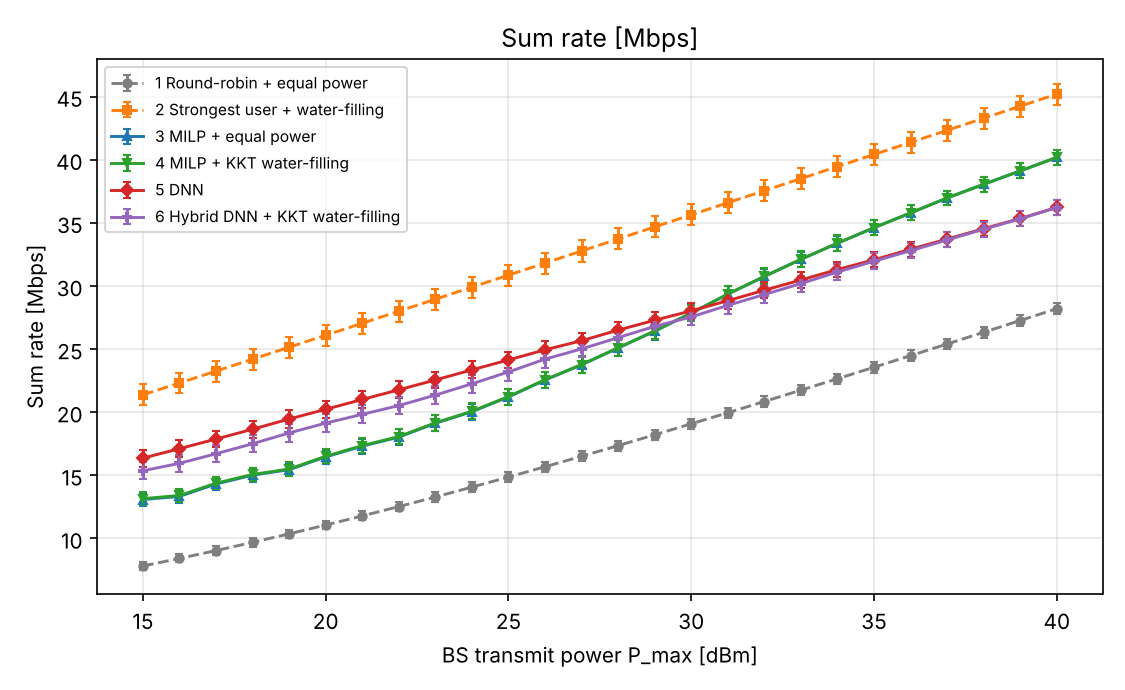

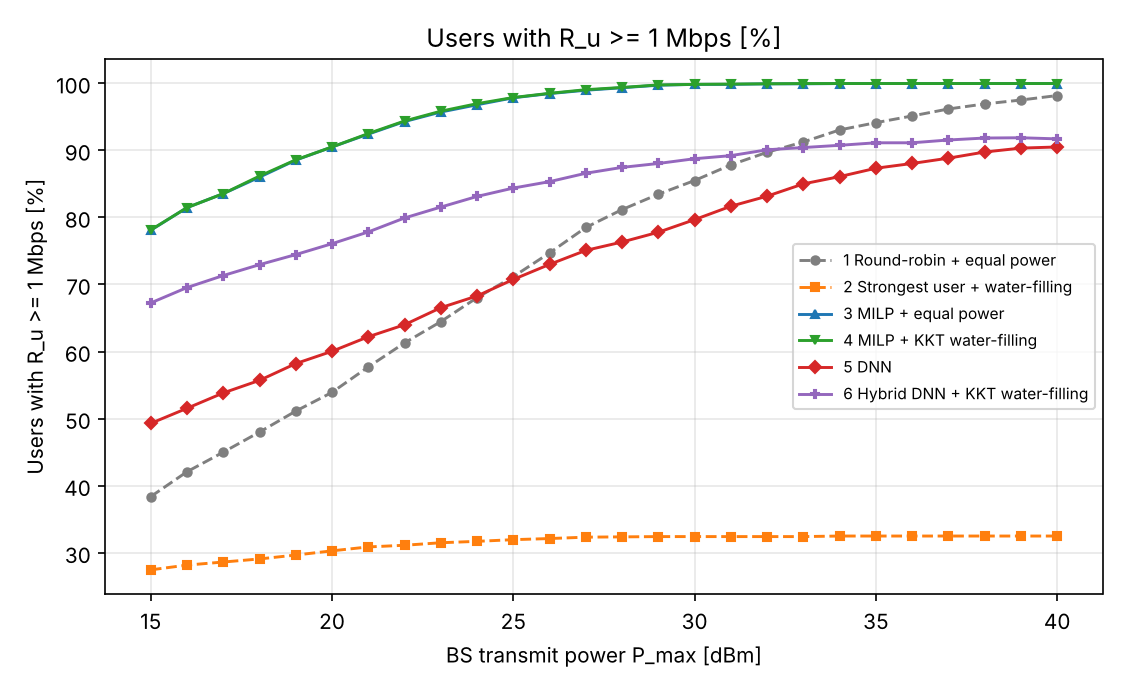

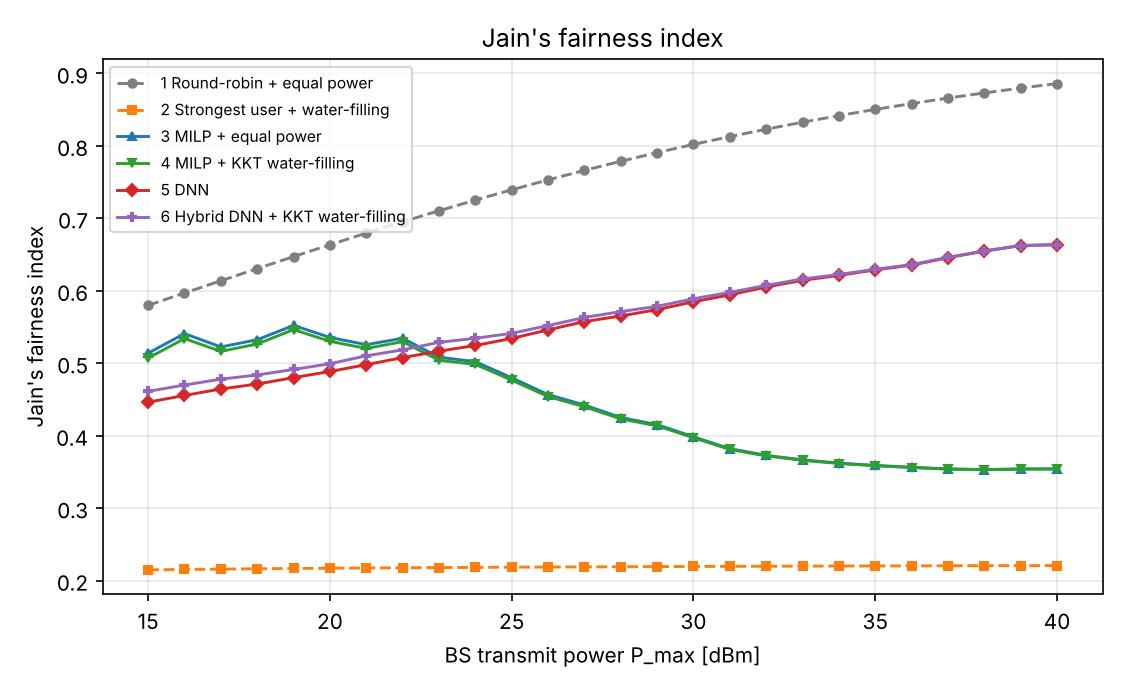

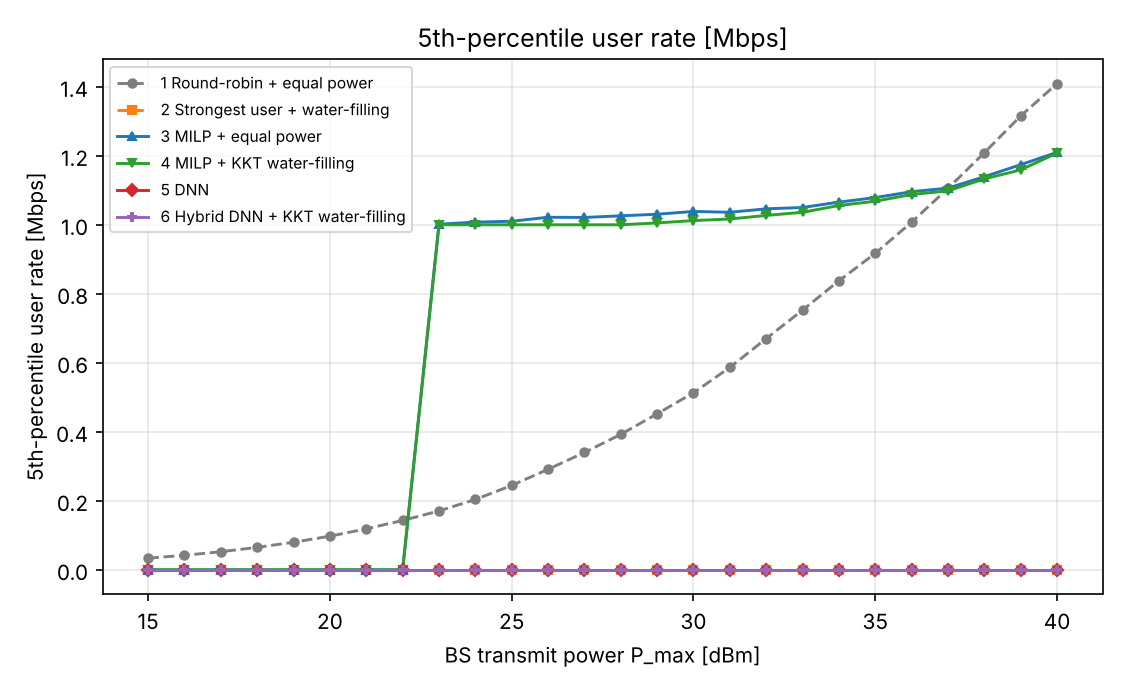

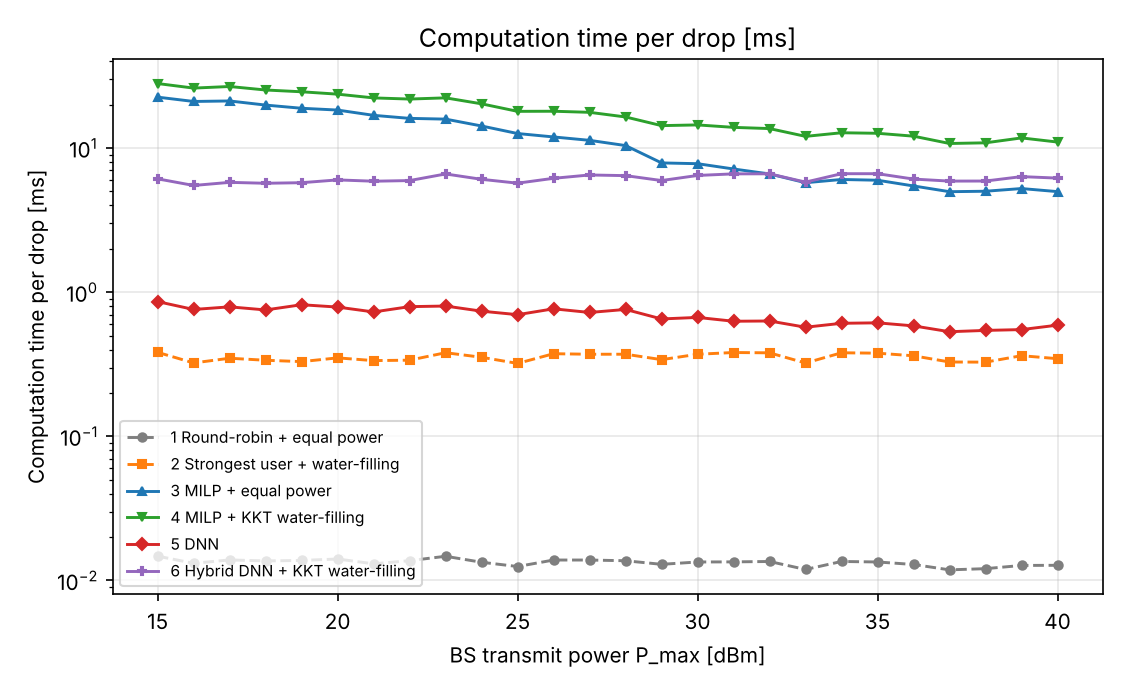

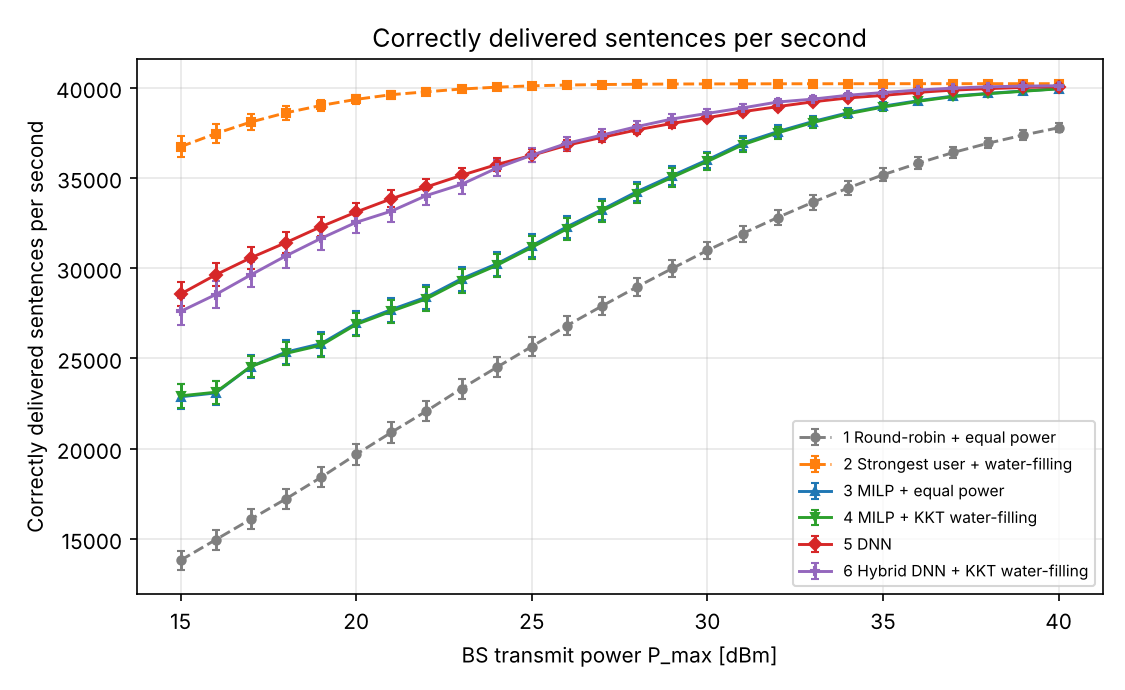

In [3]:
from IPython.display import Image, display
for f in ["sum_rate_vs_power", "qos_satisfaction_vs_power", "jain_fairness_vs_power", "p5_user_rate_vs_power", "computation_time_vs_power", "sentences_per_second_vs_power"]:
    display(Image(filename=str(F / (f + ".png"))))

## Observations (numbers from `task3_summary_all_methods.csv`)
* **15 dBm** – method 1: 7.8 Mbps, 38 % QoS, 13,815 sent/s; method 2: 21.4 Mbps, 27 % QoS, 36,735 sent/s; method 3: 13.1 Mbps, 78 % QoS, 22,876 sent/s; method 4: 13.2 Mbps, 78 % QoS, 22,929 sent/s; method 5: 16.4 Mbps, 49 % QoS, 28,572 sent/s; method 6: 15.4 Mbps, 67 % QoS, 27,608 sent/s
* **25 dBm** – method 1: 14.9 Mbps, 71 % QoS, 25,664 sent/s; method 2: 30.9 Mbps, 32 % QoS, 40,112 sent/s; method 3: 21.2 Mbps, 98 % QoS, 31,246 sent/s; method 4: 21.2 Mbps, 98 % QoS, 31,157 sent/s; method 5: 24.1 Mbps, 71 % QoS, 36,258 sent/s; method 6: 23.2 Mbps, 84 % QoS, 36,268 sent/s
* **40 dBm** – method 1: 28.2 Mbps, 98 % QoS, 37,787 sent/s; method 2: 45.2 Mbps, 32 % QoS, 40,231 sent/s; method 3: 40.2 Mbps, 100 % QoS, 39,954 sent/s; method 4: 40.2 Mbps, 100 % QoS, 39,945 sent/s; method 5: 36.2 Mbps, 90 % QoS, 40,070 sent/s; method 6: 36.2 Mbps, 92 % QoS, 40,116 sent/s

Further reading of the figures is left to the README Task 3 section, which lists the conclusions together with the limitations (300 drops per point, QoS infeasibility at low power, DNN trained with one model for all powers, AMC assumptions above).